# Data Cleaning and Feature Engineering

This notebook reproduces the source cleaning rules on the supplied per-model, last-10-observation raw files. The clone does not include the full daily 2019 source archive; its supplied files are already restricted to each drive’s final observations and have their failure labels expanded for failed drives. The label audit below checks that supplied label state against the corresponding last-day file without pretending to regenerate unavailable daily history.

## Paths and Source Models

In [1]:
from pathlib import Path
import gc
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_DIR = Path.cwd()
while not (PROJECT_DIR / "data" / "raw").is_dir():
    if PROJECT_DIR == PROJECT_DIR.parent:
        raise FileNotFoundError("Could not locate project data/raw directory")
    PROJECT_DIR = PROJECT_DIR.parent
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
SPLIT_DIR = PROJECT_DIR / "data" / "train_test"
REPORT_DIR = PROJECT_DIR / "results" / "reports"
PLOT_DIR = PROJECT_DIR / "results" / "plots"
for folder in (PROCESSED_DIR, SPLIT_DIR, REPORT_DIR, PLOT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
SOURCE_MODELS = ["ST12000NM0007", "ST4000DM000", "ST8000DM002", "ST8000NM0055", "TOSHIBA MQ01ABF050"]
CORE_SMART = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw", "smart_198_raw"]
raw_paths = sorted(RAW_DIR.glob("*_last_10_day_all_q_raw.csv"))
model_names = [p.name.removesuffix("_last_10_day_all_q_raw.csv") for p in raw_paths]


## Failure-Label Generation Audit

The source `data_cleaning/post_sort.py` back-propagates a failure over the preceding ten observations, then the cleaning notebook keeps each drive’s last ten observations. The supplied files are already-derived outputs, not the full daily archive. This notebook re-applies the source failure-window label using each serial number’s supplied last-day label, first reports any original label discrepancies, and verifies the regenerated labels.

In [2]:
label_audit_rows = []
for model_name in model_names:
    last10 = pd.read_csv(RAW_DIR / f"{model_name}_last_10_day_all_q_raw.csv",
                         usecols=["serial_number", "failure"], low_memory=False)
    lastday = pd.read_csv(RAW_DIR / f"{model_name}_last_day_all_q_raw.csv",
                          usecols=["serial_number", "failure"], low_memory=False)
    terminal_labels = lastday.drop_duplicates("serial_number", keep="last").set_index("serial_number")["failure"]
    expected = last10["serial_number"].map(terminal_labels)
    mismatch = expected.isna() | last10["failure"].ne(expected)
    per_drive_rows = last10.groupby("serial_number").size()
    label_audit_rows.append({"model": model_name, "last10_rows": len(last10),
                             "unique_drives": int(last10["serial_number"].nunique()),
                             "observations_per_drive_min": int(per_drive_rows.min()),
                             "observations_per_drive_max": int(per_drive_rows.max()),
                             "terminal_failure_drives": int(lastday["failure"].sum()),
                             "label_mismatches_vs_last_day": int(mismatch.sum()),
                             "serials_missing_from_last_day": int(expected.isna().sum())})
    del last10, lastday
    gc.collect()
label_audit = pd.DataFrame(label_audit_rows)
display(label_audit)


,model,last10_rows,unique_drives,observations_per_drive_min,observations_per_drive_max,terminal_failure_drives,label_mismatches_vs_last_day,serials_missing_from_last_day
0,HGST HMS5C4040BLE640,144513,14606,3,10,57,0,0
1,ST12000NM0007,382305,38256,1,10,1134,10,0
2,ST4000DM000,233596,23394,1,10,401,0,0
3,ST8000DM002,99325,9936,2,10,122,0,0
4,ST8000NM0055,146709,14679,1,10,221,0,0
5,TOSHIBA MQ01ABF050,5335,534,5,10,78,1,0


## Initial Schema and Column Inventory

In [3]:
schema_rows = []
for path in raw_paths:
    model_name = path.name.removesuffix("_last_10_day_all_q_raw.csv")
    columns = pd.read_csv(path, nrows=0).columns.tolist()
    smart = [c for c in columns if c.startswith("smart_") and c.endswith("_raw")]
    metadata = [c for c in columns if c not in smart and c != "failure"]
    schema_rows.append({"model": model_name, "initial_column_count": len(columns),
                        "metadata_columns": metadata, "label_column": "failure",
                        "available_SMART_attributes": smart,
                        "SMART_attribute_count": len(smart)})
schema_table = pd.DataFrame(schema_rows)
display(schema_table[["model", "initial_column_count", "metadata_columns", "SMART_attribute_count", "label_column"]])
for row in schema_rows:
    print(f"\n{row['model']} — {row['initial_column_count']} original columns")
    display(pd.DataFrame({"original_column": row["metadata_columns"] + ["failure"] + row["available_SMART_attributes"]}))

,model,initial_column_count,metadata_columns,SMART_attribute_count,label_column
0,HGST HMS5C4040BLE640,21,"[date, serial_number, model, capacity_bytes]",16,failure
1,ST12000NM0007,24,"[date, serial_number, model, capacity_bytes]",19,failure
2,ST4000DM000,26,"[date, serial_number, model, capacity_bytes]",21,failure
3,ST8000DM002,26,"[date, serial_number, model, capacity_bytes]",21,failure
4,ST8000NM0055,26,"[date, serial_number, model, capacity_bytes]",21,failure
5,TOSHIBA MQ01ABF050,19,"[date, serial_number, model, capacity_bytes]",14,failure



HGST HMS5C4040BLE640 — 21 original columns


,original_column
0,date
1,serial_number
2,model
3,capacity_bytes
4,failure
5,smart_1_raw
6,smart_2_raw
7,smart_3_raw
8,smart_4_raw
9,smart_5_raw



ST12000NM0007 — 24 original columns


,original_column
0,date
1,serial_number
2,model
3,capacity_bytes
4,failure
5,smart_1_raw
6,smart_4_raw
7,smart_5_raw
8,smart_7_raw
9,smart_9_raw



ST4000DM000 — 26 original columns


... (3 outputs left out)


ST8000NM0055 — 26 original columns


,original_column
0,date
1,serial_number
2,model
3,capacity_bytes
4,failure
5,smart_1_raw
6,smart_4_raw
7,smart_5_raw
8,smart_7_raw
9,smart_9_raw



TOSHIBA MQ01ABF050 — 19 original columns


,original_column
0,date
1,serial_number
2,model
3,capacity_bytes
4,failure
5,smart_3_raw
6,smart_4_raw
7,smart_5_raw
8,smart_9_raw
9,smart_12_raw


## Source Cleaning Rules

The original cleaning notebook drops all-null columns, drops rows containing any remaining missing values, removes constant columns except `model` and `capacity_bytes`, and sorts by `serial_number` then `date`. The final supervised model inputs are all retained raw SMART columns; the five SMART attributes below are for the separate source correlation analysis only.

In [4]:
raw_frames = {}
initial_columns = {}
initial_missing_counts = {}
initial_rows = {}
for path in raw_paths:
    model_name = path.name.removesuffix("_last_10_day_all_q_raw.csv")
    frame = pd.read_csv(path, low_memory=False)
    raw_frames[model_name] = frame
    initial_columns[model_name] = frame.columns.tolist()
    initial_rows[model_name] = len(frame)
    initial_missing_counts[model_name] = frame.isna().sum().to_dict()
    print(f"{model_name}: initial shape {frame.shape}")

HGST HMS5C4040BLE640: initial shape (144513, 21)


ST12000NM0007: initial shape (382305, 24)
ST4000DM000: initial shape (233596, 26)


ST8000DM002: initial shape (99325, 26)
ST8000NM0055: initial shape (146709, 26)
TOSHIBA MQ01ABF050: initial shape (5335, 19)


### Reapply the Source Failure-Window Labels

In [5]:
label_generation_rows = []
for model_name, frame in raw_frames.items():
    terminal = pd.read_csv(RAW_DIR / f"{model_name}_last_day_all_q_raw.csv",
                           usecols=["serial_number", "failure"], low_memory=False)
    terminal_labels = terminal.drop_duplicates("serial_number", keep="last").set_index("serial_number")["failure"]
    generated = frame["serial_number"].map(terminal_labels)
    if generated.isna().any():
        raise ValueError(f"Terminal failure labels are missing for {model_name}")
    before = frame["failure"].astype(int)
    after = generated.astype(int)
    label_generation_rows.append({"model": model_name, "rows": len(frame),
                                  "failure_rows_before": int(before.sum()),
                                  "failure_rows_after": int(after.sum()),
                                  "labels_changed": int(before.ne(after).sum()),
                                  "failed_terminal_drives": int(terminal["failure"].sum())})
    frame["failure"] = after
    del terminal
label_generation = pd.DataFrame(label_generation_rows)
display(label_generation)

,model,rows,failure_rows_before,failure_rows_after,labels_changed,failed_terminal_drives
0,HGST HMS5C4040BLE640,144513,562,562,0,57
1,ST12000NM0007,382305,11257,11247,10,1134
2,ST4000DM000,233596,3967,3967,0,401
3,ST8000DM002,99325,1193,1193,0,122
4,ST8000NM0055,146709,2179,2179,0,221
5,TOSHIBA MQ01ABF050,5335,776,775,1,78


### Verify Regenerated Failure Labels

In [6]:
post_label_audit_rows = []
for model_name, frame in raw_frames.items():
    terminal = pd.read_csv(RAW_DIR / f"{model_name}_last_day_all_q_raw.csv",
                           usecols=["serial_number", "failure"], low_memory=False)
    terminal_labels = terminal.drop_duplicates("serial_number", keep="last").set_index("serial_number")["failure"]
    expected = frame["serial_number"].map(terminal_labels)
    post_label_audit_rows.append({"model": model_name,
                                  "label_mismatches_after_generation": int(frame["failure"].ne(expected).sum())})
    del terminal
post_label_audit = pd.DataFrame(post_label_audit_rows)
label_audit = label_audit.merge(
    label_generation[["model", "labels_changed"]], on="model", validate="one_to_one")
label_audit = label_audit.merge(post_label_audit, on="model", validate="one_to_one")
display(label_audit[["model", "label_mismatches_vs_last_day", "labels_changed",
                     "label_mismatches_after_generation"]])

,model,label_mismatches_vs_last_day,labels_changed,label_mismatches_after_generation
0,HGST HMS5C4040BLE640,0,0,0
1,ST12000NM0007,10,10,0
2,ST4000DM000,0,0,0
3,ST8000DM002,0,0,0
4,ST8000NM0055,0,0,0
5,TOSHIBA MQ01ABF050,1,1,0


### All-Null Column Removal

In [7]:
all_null_columns = {}
shape_after_all_null = {}
for model_name, frame in raw_frames.items():
    removed = frame.columns[frame.isna().all()].tolist()
    all_null_columns[model_name] = removed
    before = frame.shape
    raw_frames[model_name] = frame.drop(columns=removed)
    shape_after_all_null[model_name] = raw_frames[model_name].shape
    print(f"{model_name}: {before} -> {shape_after_all_null[model_name]}; removed={removed}")

HGST HMS5C4040BLE640: (144513, 21) -> (144513, 21); removed=[]
ST12000NM0007: (382305, 24) -> (382305, 24); removed=[]
ST4000DM000: (233596, 26) -> (233596, 26); removed=[]
ST8000DM002: (99325, 26) -> (99325, 26); removed=[]
ST8000NM0055: (146709, 26) -> (146709, 26); removed=[]
TOSHIBA MQ01ABF050: (5335, 19) -> (5335, 19); removed=[]


### Missing-Value Row Removal

In [8]:
rows_with_missing = {}
shape_after_dropna = {}
for model_name, frame in raw_frames.items():
    rows_with_missing[model_name] = int(frame.isna().any(axis=1).sum())
    before_rows = len(frame)
    raw_frames[model_name] = frame.dropna()
    shape_after_dropna[model_name] = raw_frames[model_name].shape
    print(f"{model_name}: {before_rows} rows -> {len(raw_frames[model_name])}; rows containing missing values removed={rows_with_missing[model_name]}")

HGST HMS5C4040BLE640: 144513 rows -> 144513; rows containing missing values removed=0
ST12000NM0007: 382305 rows -> 382305; rows containing missing values removed=0


ST4000DM000: 233596 rows -> 233596; rows containing missing values removed=0
ST8000DM002: 99325 rows -> 99325; rows containing missing values removed=0
ST8000NM0055: 146709 rows -> 146709; rows containing missing values removed=0
TOSHIBA MQ01ABF050: 5335 rows -> 5335; rows containing missing values removed=0


### Constant Column Removal

In [9]:
constant_columns = {}
shape_after_constants = {}
for model_name, frame in raw_frames.items():
    removed = [column for column in frame.columns
               if column not in {"model", "capacity_bytes"}
               and frame[column].nunique(dropna=True) <= 1]
    constant_columns[model_name] = removed
    before = frame.shape
    raw_frames[model_name] = frame.drop(columns=removed)
    shape_after_constants[model_name] = raw_frames[model_name].shape
    print(f"{model_name}: {before} -> {shape_after_constants[model_name]}; constant columns removed={removed}")

HGST HMS5C4040BLE640: (144513, 21) -> (144513, 21); constant columns removed=[]


ST12000NM0007: (382305, 24) -> (382305, 24); constant columns removed=[]


ST4000DM000: (233596, 26) -> (233596, 26); constant columns removed=[]
ST8000DM002: (99325, 26) -> (99325, 26); constant columns removed=[]
ST8000NM0055: (146709, 26) -> (146709, 26); constant columns removed=[]
TOSHIBA MQ01ABF050: (5335, 19) -> (5335, 19); constant columns removed=[]


### Sort and Save Cleaned Datasets

In [10]:
cleaned_frames = {}
for model_name, frame in raw_frames.items():
    cleaned = frame.sort_values(["serial_number", "date"], ascending=[True, True], kind="mergesort")
    cleaned_frames[model_name] = cleaned
    output_path = PROCESSED_DIR / f"{model_name}.csv"
    cleaned.to_csv(output_path, index=False)
    print(f"{model_name}: final shape {cleaned.shape}; saved {output_path.relative_to(PROJECT_DIR)}")

HGST HMS5C4040BLE640: final shape (144513, 21); saved data/processed/HGST HMS5C4040BLE640.csv


ST12000NM0007: final shape (382305, 24); saved data/processed/ST12000NM0007.csv


ST4000DM000: final shape (233596, 26); saved data/processed/ST4000DM000.csv


ST8000DM002: final shape (99325, 26); saved data/processed/ST8000DM002.csv


ST8000NM0055: final shape (146709, 26); saved data/processed/ST8000NM0055.csv
TOSHIBA MQ01ABF050: final shape (5335, 19); saved data/processed/TOSHIBA MQ01ABF050.csv


### Cleaning Summary and Column-Level Lineage

In [11]:
lineage_rows = []
feature_manifest = {}
for model_name, cleaned in cleaned_frames.items():
    columns = initial_columns[model_name]
    smart_columns = [c for c in cleaned.columns if c.startswith("smart_") and c.endswith("_raw")]
    metadata_columns = [c for c in cleaned.columns if c not in smart_columns and c != "failure"]
    feature_manifest[model_name] = {
        "source_file": f"{model_name}_last_10_day_all_q_raw.csv",
        "features": smart_columns,
        "metadata_and_label_columns": metadata_columns + ["failure"],
        "all_null_columns_removed": all_null_columns[model_name],
        "constant_columns_removed": constant_columns[model_name]
    }
    for column in columns:
        is_smart = column.startswith("smart_") and column.endswith("_raw")
        if column in all_null_columns[model_name]:
            disposition, reason = "removed", "all values missing"
        elif column in constant_columns[model_name]:
            disposition, reason = "removed", "constant after complete-case row removal"
        else:
            disposition, reason = "retained", "source cleaning retained this column"
        lineage_rows.append({"model": model_name, "column": column,
                             "category": "SMART" if is_smart else ("label" if column == "failure" else "metadata"),
                             "initial_column_count": len(columns),
                             "missing_values_before_cleaning": int(initial_missing_counts[model_name][column]),
                             "column_disposition": disposition, "reason": reason,
                             "final_model_feature": bool(column in smart_columns and model_name in SOURCE_MODELS)})
column_lineage = pd.DataFrame(lineage_rows)
display(column_lineage.groupby(["model", "column_disposition"]).size().unstack(fill_value=0))

column_disposition,retained
model,
HGST HMS5C4040BLE640,21
ST12000NM0007,24
ST4000DM000,26
ST8000DM002,26
ST8000NM0055,26
TOSHIBA MQ01ABF050,19


In [12]:
cleaning_summary_rows = []
for model_name, cleaned in cleaned_frames.items():
    cleaning_summary_rows.append({
        "model": model_name, "rows_before": initial_rows[model_name],
        "columns_before": len(initial_columns[model_name]),
        "all_null_columns_removed": all_null_columns[model_name],
        "rows_with_missing_removed": rows_with_missing[model_name],
        "rows_after_dropna": shape_after_dropna[model_name][0],
        "constant_columns_removed": constant_columns[model_name],
        "columns_after_cleaning": len(cleaned.columns),
        "final_SMART_features": len(feature_manifest[model_name]["features"]),
        "processed_file": str((PROCESSED_DIR / f"{model_name}.csv").relative_to(PROJECT_DIR))
    })
cleaning_summary = pd.DataFrame(cleaning_summary_rows)
display(cleaning_summary)
del raw_frames, cleaned_frames

,model,rows_before,columns_before,all_null_columns_removed,rows_with_missing_removed,rows_after_dropna,constant_columns_removed,columns_after_cleaning,final_SMART_features,processed_file
0,HGST HMS5C4040BLE640,144513,21,[],0,144513,[],21,16,data/processed/HGST HMS5C4040BLE640.csv
1,ST12000NM0007,382305,24,[],0,382305,[],24,19,data/processed/ST12000NM0007.csv
2,ST4000DM000,233596,26,[],0,233596,[],26,21,data/processed/ST4000DM000.csv
3,ST8000DM002,99325,26,[],0,99325,[],26,21,data/processed/ST8000DM002.csv
4,ST8000NM0055,146709,26,[],0,146709,[],26,21,data/processed/ST8000NM0055.csv
5,TOSHIBA MQ01ABF050,5335,19,[],0,5335,[],19,14,data/processed/TOSHIBA MQ01ABF050.csv


## Column Lineage for Every Source HDD Model

In [13]:
display(column_lineage.sort_values(["model", "category", "column"]).reset_index(drop=True))
print("Complete per-model original column lists:")
for model_name in model_names:
    model_lineage = column_lineage[column_lineage["model"] == model_name]
    print(f"\n{model_name}: {len(model_lineage)} initial columns")
    display(model_lineage[["column", "category", "missing_values_before_cleaning",
                           "column_disposition", "reason", "final_model_feature"]])


,model,column,category,initial_column_count,missing_values_before_cleaning,column_disposition,reason,final_model_feature
0,HGST HMS5C4040BLE640,smart_10_raw,SMART,21,0,retained,source cleaning retained this column,False
1,HGST HMS5C4040BLE640,smart_12_raw,SMART,21,0,retained,source cleaning retained this column,False
2,HGST HMS5C4040BLE640,smart_192_raw,SMART,21,0,retained,source cleaning retained this column,False
3,HGST HMS5C4040BLE640,smart_193_raw,SMART,21,0,retained,source cleaning retained this column,False
4,HGST HMS5C4040BLE640,smart_194_raw,SMART,21,0,retained,source cleaning retained this column,False
...,...,...,...,...,...,...,...,...
137,TOSHIBA MQ01ABF050,failure,label,19,0,retained,source cleaning retained this column,False
138,TOSHIBA MQ01ABF050,capacity_bytes,metadata,19,0,retained,source cleaning retained this column,False
139,TOSHIBA MQ01ABF050,date,metadata,19,0,retained,source cleaning retained this column,False
140,TOSHIBA MQ01ABF050,model,metadata,19,0,retained,source cleaning retained this column,False


Complete per-model original column lists:

HGST HMS5C4040BLE640: 21 initial columns


,column,category,missing_values_before_cleaning,column_disposition,reason,final_model_feature
0,date,metadata,0,retained,source cleaning retained this column,False
1,serial_number,metadata,0,retained,source cleaning retained this column,False
2,model,metadata,0,retained,source cleaning retained this column,False
3,capacity_bytes,metadata,0,retained,source cleaning retained this column,False
4,failure,label,0,retained,source cleaning retained this column,False
5,smart_1_raw,SMART,0,retained,source cleaning retained this column,False
6,smart_2_raw,SMART,0,retained,source cleaning retained this column,False
7,smart_3_raw,SMART,0,retained,source cleaning retained this column,False
8,smart_4_raw,SMART,0,retained,source cleaning retained this column,False
9,smart_5_raw,SMART,0,retained,source cleaning retained this column,False



ST12000NM0007: 24 initial columns


,column,category,missing_values_before_cleaning,column_disposition,reason,final_model_feature
21,date,metadata,0,retained,source cleaning retained this column,False
22,serial_number,metadata,0,retained,source cleaning retained this column,False
23,model,metadata,0,retained,source cleaning retained this column,False
24,capacity_bytes,metadata,0,retained,source cleaning retained this column,False
25,failure,label,0,retained,source cleaning retained this column,False
26,smart_1_raw,SMART,0,retained,source cleaning retained this column,True
27,smart_4_raw,SMART,0,retained,source cleaning retained this column,True
28,smart_5_raw,SMART,0,retained,source cleaning retained this column,True
29,smart_7_raw,SMART,0,retained,source cleaning retained this column,True
30,smart_9_raw,SMART,0,retained,source cleaning retained this column,True



ST4000DM000: 26 initial columns


... (3 outputs left out)


ST8000NM0055: 26 initial columns


,column,category,missing_values_before_cleaning,column_disposition,reason,final_model_feature
97,date,metadata,0,retained,source cleaning retained this column,False
98,serial_number,metadata,0,retained,source cleaning retained this column,False
99,model,metadata,0,retained,source cleaning retained this column,False
100,capacity_bytes,metadata,0,retained,source cleaning retained this column,False
101,failure,label,0,retained,source cleaning retained this column,False
102,smart_1_raw,SMART,0,retained,source cleaning retained this column,True
103,smart_4_raw,SMART,0,retained,source cleaning retained this column,True
104,smart_5_raw,SMART,0,retained,source cleaning retained this column,True
105,smart_7_raw,SMART,0,retained,source cleaning retained this column,True
106,smart_9_raw,SMART,0,retained,source cleaning retained this column,True



TOSHIBA MQ01ABF050: 19 initial columns


,column,category,missing_values_before_cleaning,column_disposition,reason,final_model_feature
123,date,metadata,0,retained,source cleaning retained this column,False
124,serial_number,metadata,0,retained,source cleaning retained this column,False
125,model,metadata,0,retained,source cleaning retained this column,False
126,capacity_bytes,metadata,0,retained,source cleaning retained this column,False
127,failure,label,0,retained,source cleaning retained this column,False
128,smart_3_raw,SMART,0,retained,source cleaning retained this column,True
129,smart_4_raw,SMART,0,retained,source cleaning retained this column,True
130,smart_5_raw,SMART,0,retained,source cleaning retained this column,True
131,smart_9_raw,SMART,0,retained,source cleaning retained this column,True
132,smart_12_raw,SMART,0,retained,source cleaning retained this column,True


## Final Model Feature Columns

In [14]:
final_feature_rows = []
for model_name in model_names:
    features = feature_manifest[model_name]["features"]
    final_feature_rows.append({"model": model_name,
                               "role": "supervised source model" if model_name in SOURCE_MODELS else "source data / correlation only",
                               "feature_count": len(features), "final_feature_columns": features})
final_feature_table = pd.DataFrame(final_feature_rows)
display(final_feature_table)


,model,role,feature_count,final_feature_columns
0,HGST HMS5C4040BLE640,source data / correlation only,16,"[smart_1_raw, smart_2_raw, smart_3_raw, smart_..."
1,ST12000NM0007,supervised source model,19,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_..."
2,ST4000DM000,supervised source model,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_..."
3,ST8000DM002,supervised source model,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_..."
4,ST8000NM0055,supervised source model,21,"[smart_1_raw, smart_4_raw, smart_5_raw, smart_..."
5,TOSHIBA MQ01ABF050,supervised source model,14,"[smart_3_raw, smart_4_raw, smart_5_raw, smart_..."


## Correlation Feature Selection

The source selects raw SMART IDs 5, 187, 188, 197, and 198 for correlation analysis. This is not the complete supervised feature set. Attributes absent from a model schema are not passed to `.corr()`; attributes removed by cleaning are separately identified.

In [15]:
correlation_trace_rows = []
correlation_columns = {}
for model_name in model_names:
    source_columns = pd.read_csv(RAW_DIR / f"{model_name}_last_10_day_all_q_raw.csv", nrows=0).columns.tolist()
    retained = feature_manifest[model_name]["features"]
    selected = []
    for attribute in CORE_SMART:
        if attribute not in source_columns:
            status = "unavailable: absent from original schema"
        elif attribute in feature_manifest[model_name]["all_null_columns_removed"]:
            status = "excluded: entirely missing"
        elif attribute in feature_manifest[model_name]["constant_columns_removed"]:
            status = "excluded: constant"
        else:
            status = "selected for correlation"
            selected.append(attribute)
        correlation_trace_rows.append({"model": model_name, "candidate_attribute": attribute,
                                       "source_available": attribute in source_columns,
                                       "selected_for_correlation": attribute in selected,
                                       "status": status})
    correlation_columns[model_name] = selected
correlation_trace = pd.DataFrame(correlation_trace_rows)
display(correlation_trace.pivot(index="model", columns="candidate_attribute", values="status"))
for model_name in model_names:
    print(f"{model_name}: selected correlation columns = {correlation_columns[model_name]}")


candidate_attribute,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw,smart_5_raw
model,,,,,
HGST HMS5C4040BLE640,unavailable: absent from original schema,unavailable: absent from original schema,selected for correlation,unavailable: absent from original schema,selected for correlation
ST12000NM0007,selected for correlation,selected for correlation,selected for correlation,selected for correlation,selected for correlation
ST4000DM000,selected for correlation,selected for correlation,selected for correlation,selected for correlation,selected for correlation
ST8000DM002,selected for correlation,selected for correlation,selected for correlation,selected for correlation,selected for correlation
ST8000NM0055,selected for correlation,selected for correlation,selected for correlation,selected for correlation,selected for correlation
TOSHIBA MQ01ABF050,unavailable: absent from original schema,unavailable: absent from original schema,selected for correlation,unavailable: absent from original schema,selected for correlation


HGST HMS5C4040BLE640: selected correlation columns = ['smart_5_raw', 'smart_197_raw']
ST12000NM0007: selected correlation columns = ['smart_5_raw', 'smart_187_raw', 'smart_188_raw', 'smart_197_raw', 'smart_198_raw']
ST4000DM000: selected correlation columns = ['smart_5_raw', 'smart_187_raw', 'smart_188_raw', 'smart_197_raw', 'smart_198_raw']
ST8000DM002: selected correlation columns = ['smart_5_raw', 'smart_187_raw', 'smart_188_raw', 'smart_197_raw', 'smart_198_raw']
ST8000NM0055: selected correlation columns = ['smart_5_raw', 'smart_187_raw', 'smart_188_raw', 'smart_197_raw', 'smart_198_raw']
TOSHIBA MQ01ABF050: selected correlation columns = ['smart_5_raw', 'smart_197_raw']


In [16]:
correlation_matrices = {}
correlation_value_rows = []
for model_name in model_names:
    selected = correlation_columns[model_name]
    if not selected:
        correlation_matrices[model_name] = pd.DataFrame()
        continue
    frame = pd.read_csv(PROCESSED_DIR / f"{model_name}.csv", usecols=selected, low_memory=False)
    correlation_matrices[model_name] = frame.corr()
    for first_attribute in selected:
        for second_attribute in selected:
            correlation_value_rows.append({"model": model_name,
                                           "attribute_1": first_attribute,
                                           "attribute_2": second_attribute,
                                           "correlation": correlation_matrices[model_name].loc[first_attribute, second_attribute]})
    print(f"{model_name}: correlation matrix inputs ({len(selected)}): {selected}")
    display(correlation_matrices[model_name])
    del frame
    gc.collect()
correlation_values = pd.DataFrame(correlation_value_rows)
display(correlation_values)
print("HGST confirmation:", correlation_columns["HGST HMS5C4040BLE640"],
      "— SMART 187, 188, and 198 are absent from its original columns.")


HGST HMS5C4040BLE640: correlation matrix inputs (2): ['smart_5_raw', 'smart_197_raw']


,smart_5_raw,smart_197_raw
smart_5_raw,1.000000,0.087663
smart_197_raw,0.087663,1.000000


ST12000NM0007: correlation matrix inputs (5): ['smart_5_raw', 'smart_187_raw', 'smart_188_raw', 'smart_197_raw', 'smart_198_raw']


,smart_5_raw,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw
smart_5_raw,1.000000,0.033520,0.046994,0.044059,0.044059
smart_187_raw,0.033520,1.000000,0.009549,0.000272,0.000272
smart_188_raw,0.046994,0.009549,1.000000,0.000624,0.000624
smart_197_raw,0.044059,0.000272,0.000624,1.000000,1.000000
smart_198_raw,0.044059,0.000272,0.000624,1.000000,1.000000


ST4000DM000: correlation matrix inputs (5): ['smart_5_raw', 'smart_187_raw', 'smart_188_raw', 'smart_197_raw', 'smart_198_raw']


,smart_5_raw,smart_187_raw,smart_188_raw,smart_197_raw,smart_198_raw
smart_5_raw,1.000000,0.055265,0.162852,0.062390,0.062390
smart_187_raw,0.055265,1.000000,0.008414,0.114791,0.114791
smart_188_raw,0.162852,0.008414,1.000000,0.000101,0.000101
smart_197_raw,0.062390,0.114791,0.000101,1.000000,1.000000
smart_198_raw,0.062390,0.114791,0.000101,1.000000,1.000000


... (4 outputs left out)

TOSHIBA MQ01ABF050: correlation matrix inputs (2): ['smart_5_raw', 'smart_197_raw']


,smart_5_raw,smart_197_raw
smart_5_raw,1.000000,0.000456
smart_197_raw,0.000456,1.000000


,model,attribute_1,attribute_2,correlation
0,HGST HMS5C4040BLE640,smart_5_raw,smart_5_raw,1.000000
1,HGST HMS5C4040BLE640,smart_5_raw,smart_197_raw,0.087663
2,HGST HMS5C4040BLE640,smart_197_raw,smart_5_raw,0.087663
3,HGST HMS5C4040BLE640,smart_197_raw,smart_197_raw,1.000000
4,ST12000NM0007,smart_5_raw,smart_5_raw,1.000000
...,...,...,...,...
103,ST8000NM0055,smart_198_raw,smart_198_raw,1.000000
104,TOSHIBA MQ01ABF050,smart_5_raw,smart_5_raw,1.000000
105,TOSHIBA MQ01ABF050,smart_5_raw,smart_197_raw,0.000456
106,TOSHIBA MQ01ABF050,smart_197_raw,smart_5_raw,0.000456


HGST confirmation: ['smart_5_raw', 'smart_197_raw'] — SMART 187, 188, and 198 are absent from its original columns.


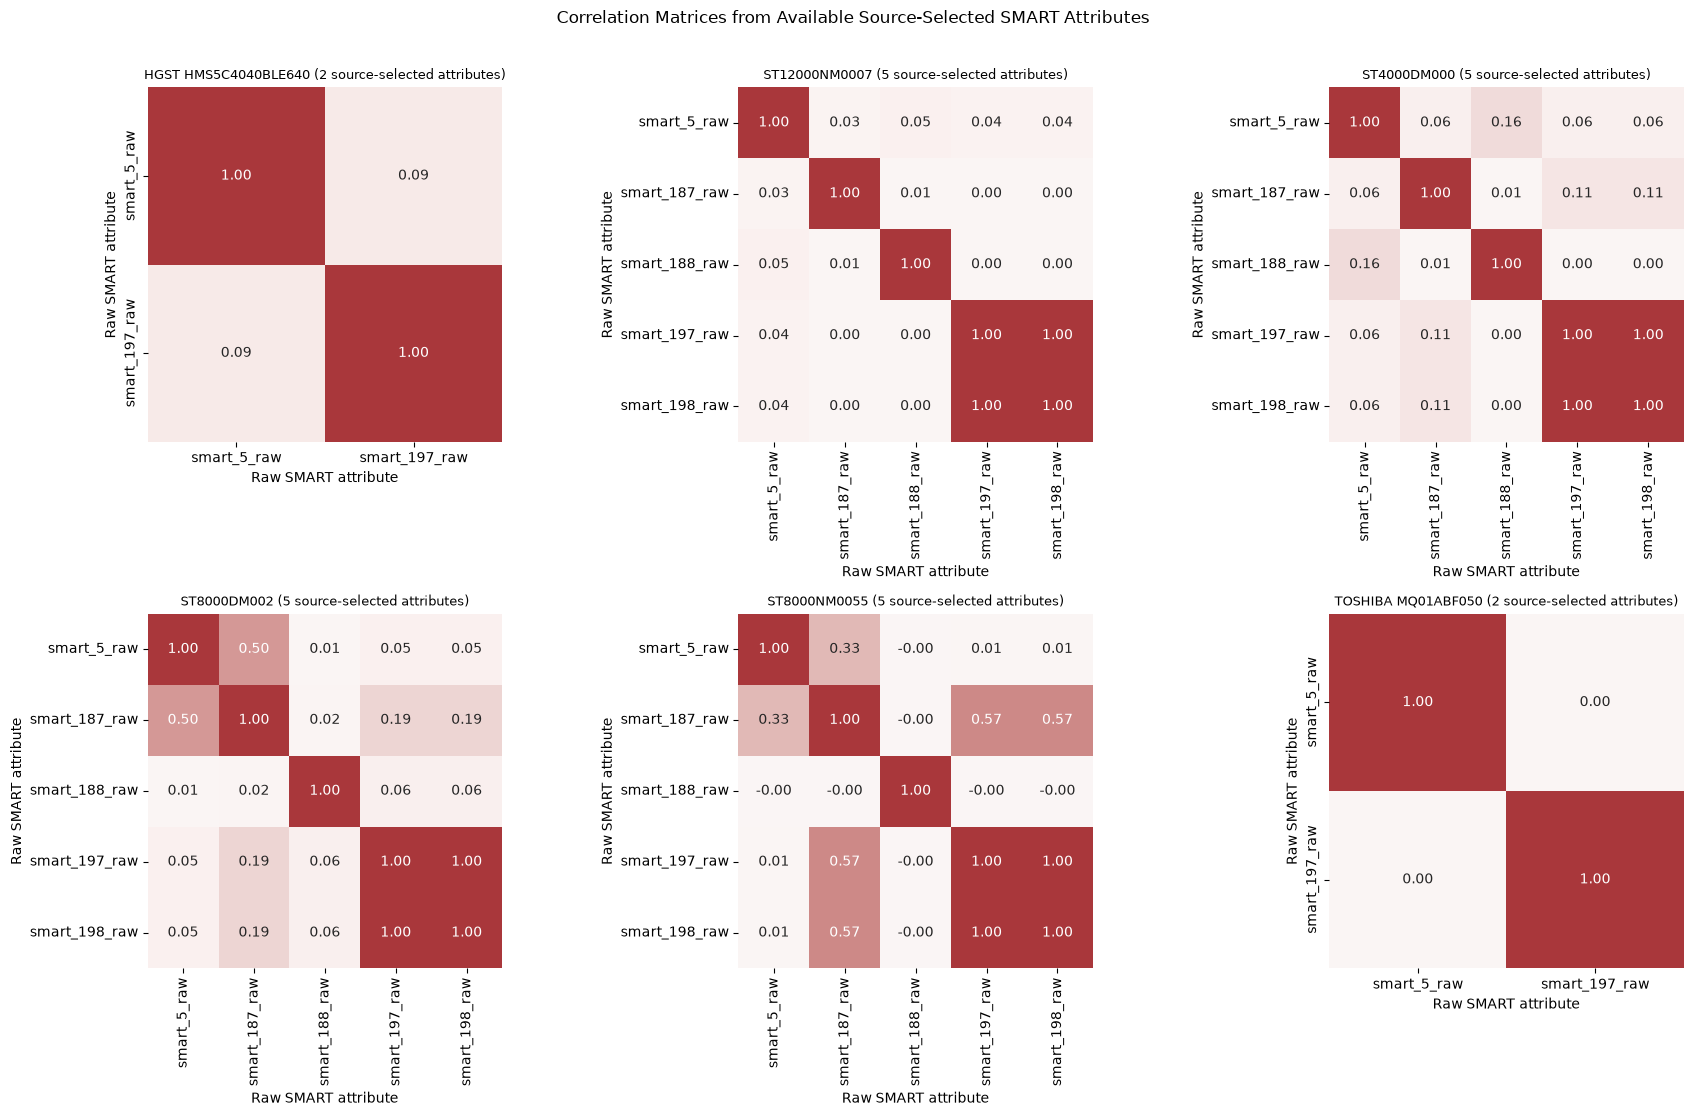

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, model_name in zip(axes.flat, model_names):
    matrix = correlation_matrices[model_name]
    if matrix.empty:
        ax.set_title(f"{model_name}: no selected SMART attributes")
        ax.set_axis_off()
    else:
        sns.heatmap(matrix, annot=True, fmt=".2f", cmap="vlag", center=0,
                    vmin=-1, vmax=1, square=True, cbar=False, ax=ax)
        ax.set_title(f"{model_name} ({len(matrix.columns)} source-selected attributes)", fontsize=9)
        ax.set_xlabel("Raw SMART attribute")
        ax.set_ylabel("Raw SMART attribute")
fig.suptitle("Correlation Matrices from Available Source-Selected SMART Attributes", y=1.01)
fig.tight_layout()
fig.savefig(PLOT_DIR / "smart_correlation_matrices.png", dpi=160, bbox_inches="tight")
plt.show()


## Chronological Train, Validation, and Test Data

The final Random Forest notebook reserves the first 80% of each label class for training and the last 20% for testing. The XGBoost notebook further splits that initial 80% into 60% train and 20% validation, leaving the same chronological 20% test tail. These files preserve those two paths: Random Forest combines `train` and `validation`; XGBoost uses `train`, `validation`, and `test` separately.

In [18]:
split_rows = []
for model_name in SOURCE_MODELS:
    data = pd.read_csv(PROCESSED_DIR / f"{model_name}.csv", parse_dates=["date"], low_memory=False)
    split_parts = {"train": [], "validation": [], "test": []}
    for label in (0, 1):
        group = data.loc[data["failure"] == label].sort_values("date")
        train80_end = int(len(group) * 0.8)
        train60_end = int(train80_end * 0.75)
        split_parts["train"].append(group.iloc[:train60_end])
        split_parts["validation"].append(group.iloc[train60_end:train80_end])
        split_parts["test"].append(group.iloc[train80_end:])
    for split_name, class_parts in split_parts.items():
        part = pd.concat(class_parts, ignore_index=True)
        part.to_csv(SPLIT_DIR / f"{model_name}_{split_name}.csv", index=False)
        split_rows.append({"model": model_name, "split": split_name, "rows": len(part),
                           "healthy": int((part.failure == 0).sum()),
                           "failed": int((part.failure == 1).sum()),
                           "date_start": part.date.min(), "date_end": part.date.max()})
    del data
    gc.collect()
split_summary = pd.DataFrame(split_rows)
display(split_summary)


,model,split,rows,healthy,failed,date_start,date_end
0,ST12000NM0007,train,229381,222634,6747,2019-01-01,2019-12-27
1,ST12000NM0007,validation,76462,74212,2250,2019-09-04,2019-12-29
2,ST12000NM0007,test,76462,74212,2250,2019-10-27,2019-12-31
3,ST4000DM000,train,140156,137777,2379,2019-01-01,2019-12-27
4,ST4000DM000,validation,46720,45926,794,2019-08-15,2019-12-29
5,ST4000DM000,test,46720,45926,794,2019-10-30,2019-12-31
6,ST8000DM002,train,59593,58878,715,2019-01-01,2019-12-27
7,ST8000DM002,validation,19866,19627,239,2019-08-29,2019-12-29
8,ST8000DM002,test,19866,19627,239,2019-10-22,2019-12-31
9,ST8000NM0055,train,88025,86718,1307,2019-01-01,2019-12-27


## Isolation Forest Split

In [19]:
isolation_model = "ST12000NM0007"
last_day = pd.read_csv(RAW_DIR / f"{isolation_model}_last_day_all_q_raw.csv",
                       parse_dates=["date"], low_memory=False)
isolation_train_parts = []
isolation_test_parts = []
for label in (0, 1):
    group = last_day.loc[last_day.failure == label].sort_values("date")
    cut = int(len(group) * 0.8)
    isolation_train_parts.append(group.iloc[:cut])
    isolation_test_parts.append(group.iloc[cut:])
isolation_train = pd.concat(isolation_train_parts, ignore_index=True)
isolation_test = pd.concat(isolation_test_parts, ignore_index=True)
isolation_train.to_csv(SPLIT_DIR / f"{isolation_model}_isolation_train.csv", index=False)
isolation_test.to_csv(SPLIT_DIR / f"{isolation_model}_isolation_test.csv", index=False)
display(pd.DataFrame([
    {"split": "isolation_train", "rows": len(isolation_train), "healthy": int((isolation_train.failure == 0).sum()), "failed": int((isolation_train.failure == 1).sum())},
    {"split": "isolation_test", "rows": len(isolation_test), "healthy": int((isolation_test.failure == 0).sum()), "failed": int((isolation_test.failure == 1).sum())}
]))


,split,rows,healthy,failed
0,isolation_train,30604,29697,907
1,isolation_test,7652,7425,227


## Save Processing and Selection Reports

In [20]:
cleaning_summary.to_csv(REPORT_DIR / "cleaning_summary.csv", index=False)
column_lineage.to_csv(REPORT_DIR / "column_lineage.csv", index=False)
correlation_trace.to_csv(REPORT_DIR / "correlation_eligibility.csv", index=False)
correlation_values.to_csv(REPORT_DIR / "smart_correlations.csv", index=False)
split_summary.to_csv(REPORT_DIR / "split_support.csv", index=False)
label_audit.to_csv(REPORT_DIR / "label_generation_audit.csv", index=False)
with (REPORT_DIR / "feature_manifest.json").open("w", encoding="utf-8") as file:
    json.dump(feature_manifest, file, indent=2)
print("Processed datasets:", len(list(PROCESSED_DIR.glob("*.csv"))))
print("Train/validation/test files:", len(list(SPLIT_DIR.glob("*_train.csv"))) + len(list(SPLIT_DIR.glob("*_validation.csv"))) + len(list(SPLIT_DIR.glob("*_test.csv"))))
print("Reports saved under", REPORT_DIR)


Processed datasets: 6
Train/validation/test files: 20
Reports saved under /run/media/yashraj221b/DATA/YASH FILES/Programming/BACKBLAZE_DRIVE/results/reports
